In [1]:
# ============================================================
# Outcome I extension — P15 broad radius-regime model
# Multinomial model for transit planets
# ============================================================

import pandas as pd
import numpy as np
import statsmodels.api as sm
from sklearn.metrics import log_loss

# Cargar catálogo con parámetros derivados
df = pd.read_csv("../data_processed/03_catalogo_con_parametros_derivados.csv")

# Revisar clases disponibles
df["clase_radio"].value_counts(dropna=False)

clase_radio
neptuniano           2374
gigante_gaseoso      1853
supertierra          1188
terrestre             571
mayor_que_jupiter     237
sin_dato               44
Name: count, dtype: int64

In [2]:
# ============================================================
# P15 — Transit sample for broad radius-regime model
# ============================================================

clases_radio = [
    "terrestre",
    "supertierra",
    "neptuniano",
    "gigante_gaseoso",
    "mayor_que_jupiter"
]

df_p15 = df[
    (df["discoverymethod"] == "Transit") &
    (df["clase_radio"].isin(clases_radio)) &
    df["pl_orbper"].notna() &
    df["st_mass"].notna() &
    df["st_met"].notna() &
    (df["pl_orbper"] > 0)
].copy()

df_p15["logP"] = np.log10(df_p15["pl_orbper"])

# Ordenar clases explícitamente
df_p15["clase_radio"] = pd.Categorical(
    df_p15["clase_radio"],
    categories=clases_radio,
    ordered=False
)

print("N planetas:", len(df_p15))
print("N sistemas:", df_p15["hostname"].nunique())

tabla_P15_sample = (
    df_p15["clase_radio"]
    .value_counts()
    .reindex(clases_radio)
    .reset_index()
)

tabla_P15_sample.columns = ["radius_class", "N_planets"]
tabla_P15_sample["fraction"] = tabla_P15_sample["N_planets"] / len(df_p15)

tabla_P15_sample.to_csv(
    "../tables/P15_broad_radius_regime_sample.csv",
    index=False
)

tabla_P15_sample

N planetas: 4461
N sistemas: 3390


,radius_class,N_planets,fraction
0,terrestre,514,0.115221
1,supertierra,1080,0.242098
2,neptuniano,1937,0.434208
3,gigante_gaseoso,720,0.161399
4,mayor_que_jupiter,210,0.047075


In [3]:
# ============================================================
# P15 — Multinomial logistic model
# Base class: supertierra
# ============================================================

# Reordenar para que supertierra sea la clase base
clases_modelo = [
    "supertierra",
    "terrestre",
    "neptuniano",
    "gigante_gaseoso",
    "mayor_que_jupiter"
]

df_p15["clase_modelo"] = pd.Categorical(
    df_p15["clase_radio"],
    categories=clases_modelo,
    ordered=False
)

# Código numérico del outcome
y_p15 = df_p15["clase_modelo"].cat.codes

# Predictores estandarizados
for var in ["logP", "st_mass", "st_met"]:
    df_p15[var + "_z"] = (
        df_p15[var] - df_p15[var].mean()
    ) / df_p15[var].std()

X_p15 = df_p15[
    [
        "logP_z",
        "st_mass_z",
        "st_met_z"
    ]
].copy()

X_p15 = sm.add_constant(X_p15)

modelo_p15 = sm.MNLogit(y_p15, X_p15).fit(
    method="newton",
    maxiter=200,
    disp=False
)

modelo_p15.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                          MNLogit Regression Results                          
==============================================================================
Dep. Variable:                      y   No. Observations:                 4461
Model:                        MNLogit   Df Residuals:                     4445
Method:                           MLE   Df Model:                           12
Date:                Fri, 21 Aug 2026   Pseudo R-squ.:                  0.1592
Time:                        09:24:34   Log-Likelihood:                -5224.3
converged:                       True   LL-Null:                       -6213.5
Covariance Type:            nonrobust   LLR p-value:                     0.000
==============================================================================
       y=1       coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const         -1.0582      0.068    -15.590      0.000      -1.191      -0.925
logP_z        -0.5010      0.067     -7.428      0.000      -0.633      -0.369
st_mass_z     -0.1822      0.061     -2.997      0.003      -0.301      -0.063
st_met_z      -0.1387      0.055     -2.504      0.012      -0.247      -0.030
------------------------------------------------------------------------------
       y=2       coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.5588      0.041     13.530      0.000       0.478       0.640
logP_z         0.8360      0.048     17.439      0.000       0.742       0.930
st_mass_z      0.0834      0.048      1.740      0.082      -0.011       0.177
st_met_z       0.2295      0.043      5.317      0.000       0.145       0.314
------------------------------------------------------------------------------
       y=3       coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const         -0.5662      0.057    -10.008      0.000      -0.677      -0.455
logP_z         0.2649      0.060      4.438      0.000       0.148       0.382
st_mass_z      0.6207      0.063      9.869      0.000       0.497       0.744
st_met_z       0.7636      0.058     13.161      0.000       0.650       0.877
------------------------------------------------------------------------------
       y=4       coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const         -3.8432      0.214    -17.970      0.000      -4.262      -3.424
logP_z        -1.6005      0.152    -10.558      0.000      -1.898      -1.303
st_mass_z      2.1838      0.121     18.078      0.000       1.947       2.421
st_met_z      -0.1218      0.108     -1.132      0.258      -0.333       0.089
==============================================================================
"""

In [4]:
# ============================================================
# P15 — Model metrics
# ============================================================

pred_p15 = modelo_p15.predict(X_p15)

# statsmodels devuelve probabilidades por clase en orden de códigos
ll_null = modelo_p15.llnull
ll_model = modelo_p15.llf

pseudo_R2_mcfadden = 1 - (ll_model / ll_null)

logloss_p15 = log_loss(
    y_p15,
    pred_p15,
    labels=np.arange(len(clases_modelo))
)

tabla_P15_metrics = pd.DataFrame({
    "model": ["P15 multinomial"],
    "sample": ["Transit planets"],
    "N_planets": [len(df_p15)],
    "N_hosts": [df_p15["hostname"].nunique()],
    "AIC": [modelo_p15.aic],
    "BIC": [modelo_p15.bic],
    "pseudo_R2_McFadden": [pseudo_R2_mcfadden],
    "log_loss": [logloss_p15]
}).round(4)

tabla_P15_metrics.to_csv(
    "../tables/P15_multinomial_model_metrics.csv",
    index=False
)

tabla_P15_metrics

,model,sample,N_planets,N_hosts,AIC,BIC,pseudo_R2_McFadden,log_loss
0,P15 multinomial,Transit planets,4461,3390,10480.594,10583.0441,0.1592,1.1711


In [5]:
# ============================================================
# P15 — Multinomial model with explicit numeric base
# Base/reference class = supertierra
# ============================================================

import pandas as pd
import numpy as np
import statsmodels.api as sm
from sklearn.metrics import log_loss

# Cargar catálogo
df = pd.read_csv("../data_processed/03_catalogo_con_parametros_derivados.csv")

# Clases usadas
clases_p15 = [
    "terrestre",
    "supertierra",
    "neptuniano",
    "gigante_gaseoso",
    "mayor_que_jupiter"
]

# Muestra transit-only
df_p15 = df[
    (df["discoverymethod"] == "Transit") &
    (df["clase_radio"].isin(clases_p15)) &
    df["pl_orbper"].notna() &
    df["st_mass"].notna() &
    df["st_met"].notna() &
    (df["pl_orbper"] > 0)
].copy()

df_p15["logP"] = np.log10(df_p15["pl_orbper"])

# Código explícito: supertierra = 0 = referencia
class_code = {
    "supertierra": 0,
    "terrestre": 1,
    "neptuniano": 2,
    "gigante_gaseoso": 3,
    "mayor_que_jupiter": 4
}

code_class = {
    0: "supertierra",
    1: "terrestre",
    2: "neptuniano",
    3: "gigante_gaseoso",
    4: "mayor_que_jupiter"
}

df_p15["class_code"] = df_p15["clase_radio"].map(class_code)

y_p15 = df_p15["class_code"].astype(int)

print("Class coding:")
print(code_class)

print("\nClass counts:")
display(
    df_p15["clase_radio"]
    .value_counts()
    .reindex(clases_p15)
)

# Predictores estandarizados
for var in ["logP", "st_mass", "st_met"]:
    df_p15[var + "_z"] = (
        df_p15[var] - df_p15[var].mean()
    ) / df_p15[var].std()

X_p15 = df_p15[
    [
        "logP_z",
        "st_mass_z",
        "st_met_z"
    ]
].copy()

X_p15 = sm.add_constant(X_p15)

modelo_p15 = sm.MNLogit(y_p15, X_p15).fit(
    method="newton",
    maxiter=200,
    disp=False
)

modelo_p15.summary()

Class coding:
{0: 'supertierra', 1: 'terrestre', 2: 'neptuniano', 3: 'gigante_gaseoso', 4: 'mayor_que_jupiter'}

Class counts:


clase_radio
terrestre             514
supertierra          1080
neptuniano           1937
gigante_gaseoso       720
mayor_que_jupiter     210
Name: count, dtype: int64

<class 'statsmodels.iolib.summary.Summary'>
"""
                          MNLogit Regression Results                          
==============================================================================
Dep. Variable:             class_code   No. Observations:                 4461
Model:                        MNLogit   Df Residuals:                     4445
Method:                           MLE   Df Model:                           12
Date:                Fri, 21 Aug 2026   Pseudo R-squ.:                  0.1592
Time:                        09:24:35   Log-Likelihood:                -5224.3
converged:                       True   LL-Null:                       -6213.5
Covariance Type:            nonrobust   LLR p-value:                     0.000
================================================================================
class_code=1       coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------
const           -1.0582      0.068    -15.590      0.000      -1.191      -0.925
logP_z          -0.5010      0.067     -7.428      0.000      -0.633      -0.369
st_mass_z       -0.1822      0.061     -2.997      0.003      -0.301      -0.063
st_met_z        -0.1387      0.055     -2.504      0.012      -0.247      -0.030
--------------------------------------------------------------------------------
class_code=2       coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------
const            0.5588      0.041     13.530      0.000       0.478       0.640
logP_z           0.8360      0.048     17.439      0.000       0.742       0.930
st_mass_z        0.0834      0.048      1.740      0.082      -0.011       0.177
st_met_z         0.2295      0.043      5.317      0.000       0.145       0.314
--------------------------------------------------------------------------------
class_code=3       coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------
const           -0.5662      0.057    -10.008      0.000      -0.677      -0.455
logP_z           0.2649      0.060      4.438      0.000       0.148       0.382
st_mass_z        0.6207      0.063      9.869      0.000       0.497       0.744
st_met_z         0.7636      0.058     13.161      0.000       0.650       0.877
--------------------------------------------------------------------------------
class_code=4       coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------
const           -3.8432      0.214    -17.970      0.000      -4.262      -3.424
logP_z          -1.6005      0.152    -10.558      0.000      -1.898      -1.303
st_mass_z        2.1838      0.121     18.078      0.000       1.947       2.421
st_met_z        -0.1218      0.108     -1.132      0.258      -0.333       0.089
================================================================================
"""

In [6]:
# ============================================================
# P15 — Model metrics
# ============================================================

pred_p15 = modelo_p15.predict(X_p15)

ll_null = modelo_p15.llnull
ll_model = modelo_p15.llf

pseudo_R2_mcfadden = 1 - (ll_model / ll_null)

logloss_p15 = log_loss(
    y_p15,
    pred_p15,
    labels=np.arange(len(clases_p15))
)

tabla_P15_metrics = pd.DataFrame({
    "model": ["P15 multinomial"],
    "sample": ["Transit planets"],
    "N_planets": [len(df_p15)],
    "N_hosts": [df_p15["hostname"].nunique()],
    "AIC": [modelo_p15.aic],
    "BIC": [modelo_p15.bic],
    "pseudo_R2_McFadden": [pseudo_R2_mcfadden],
    "log_loss": [logloss_p15]
}).round(4)

tabla_P15_metrics.to_csv(
    "../tables/P15_multinomial_model_metrics.csv",
    index=False
)

tabla_P15_metrics

,model,sample,N_planets,N_hosts,AIC,BIC,pseudo_R2_McFadden,log_loss
0,P15 multinomial,Transit planets,4461,3390,10480.594,10583.0441,0.1592,1.1711


Stellar mass and metallicity do not affect all planet-radius regimes in the same way. Metallicity is most clearly associated with Neptune-like and gas-giant regimes relative to super-Earths, while stellar mass is especially strong for giant and larger-than-Jupiter planets. For terrestrial planets, both stellar mass and metallicity are negative relative to super-Earths.

In [7]:
# ============================================================
# P15 — Clean RRR table for report/poster
# ============================================================

tabla_P15_RRR_wide = tabla_P15_coef_long.pivot_table(
    index="predictor",
    columns="class_vs_supertierra",
    values="RRR"
).reindex(["logP_z", "st_mass_z", "st_met_z"])

tabla_P15_RRR_wide = tabla_P15_RRR_wide[
    [
        "terrestre",
        "neptuniano",
        "gigante_gaseoso",
        "mayor_que_jupiter"
    ]
].round(2)

tabla_P15_RRR_wide.to_csv(
    "../tables/P15_multinomial_RRR_wide_vs_supertierra.csv"
)

tabla_P15_RRR_wide

NameError: name 'tabla_P15_coef_long' is not defined

A multinomial model of transit planets shows that the stellar parameters associated with planet regime are not uniform across radius classes. Relative to super-Earths, Neptune-like and gas-giant planets are favored around more metal-rich stars, while gas giants and larger-than-Jupiter planets show the strongest positive association with stellar mass. Terrestrial planets show negative associations with both stellar mass and metallicity relative to super-Earths.

In [ ]:
# ============================================================
# P15 — Model metrics
# ============================================================

pred_p15 = modelo_p15.predict(X_p15)

pseudo_R2_mcfadden = 1 - (modelo_p15.llf / modelo_p15.llnull)

logloss_p15 = log_loss(
    y_p15,
    pred_p15,
    labels=[0, 1, 2, 3, 4]
)

tabla_P15_metrics = pd.DataFrame({
    "model": ["P15 multinomial"],
    "sample": ["Transit planets"],
    "N_planets": [len(df_p15)],
    "N_hosts": [df_p15["hostname"].nunique()],
    "AIC": [modelo_p15.aic],
    "BIC": [modelo_p15.bic],
    "pseudo_R2_McFadden": [pseudo_R2_mcfadden],
    "log_loss": [logloss_p15]
}).round(4)

tabla_P15_metrics.to_csv(
    "../tables/P15_multinomial_model_metrics.csv",
    index=False
)

tabla_P15_metrics

In [ ]:
# ============================================================
# P15 — Add significance stars for display
# ============================================================

def sig_star(p):
    if p < 0.001:
        return "***"
    elif p < 0.01:
        return "**"
    elif p < 0.05:
        return "*"
    elif p < 0.1:
        return "."
    else:
        return ""

tabla_P15_display = tabla_P15_coef_long.copy()
tabla_P15_display["RRR_display"] = (
    tabla_P15_display["RRR"].round(2).astype(str)
    + tabla_P15_display["p_value"].apply(sig_star)
)

tabla_P15_RRR_display_wide = tabla_P15_display.pivot_table(
    index="predictor",
    columns="class_vs_supertierra",
    values="RRR_display",
    aggfunc="first"
).reindex(["logP_z", "st_mass_z", "st_met_z"])

tabla_P15_RRR_display_wide = tabla_P15_RRR_display_wide[
    [
        "terrestre",
        "neptuniano",
        "gigante_gaseoso",
        "mayor_que_jupiter"
    ]
]

tabla_P15_RRR_display_wide.to_csv(
    "../tables/P15_multinomial_RRR_display_vs_supertierra.csv"
)

tabla_P15_RRR_display_wide

A multinomial model of transit planets shows that the stellar parameters associated with planet regime are not uniform across radius classes. Relative to super-Earths, Neptune-like and gas-giant planets are favored around more metal-rich stars, while gas giants and larger-than-Jupiter planets show the strongest positive association with stellar mass. Terrestrial planets show negative associations with both stellar mass and metallicity relative to super-Earths.

In [ ]:
# ============================================================
# P16 — Stellar-information gain by radius regime
#
# B0: class ~ logP
# B1: class ~ logP + Mstar + [Fe/H]
#
# Goal:
# Measure where stellar information improves radius-regime prediction.
# ============================================================

import pandas as pd
import numpy as np
import statsmodels.api as sm
import matplotlib.pyplot as plt

from sklearn.metrics import log_loss, roc_auc_score

# ------------------------------------------------------------
# Use df_p15 from P15 if available.
# Otherwise reconstruct it.
# ------------------------------------------------------------

try:
    df_p15
    y_p15
except NameError:
    df = pd.read_csv("../data_processed/03_catalogo_con_parametros_derivados.csv")

    clases_p15 = [
        "terrestre",
        "supertierra",
        "neptuniano",
        "gigante_gaseoso",
        "mayor_que_jupiter"
    ]

    df_p15 = df[
        (df["discoverymethod"] == "Transit") &
        (df["clase_radio"].isin(clases_p15)) &
        df["pl_orbper"].notna() &
        df["st_mass"].notna() &
        df["st_met"].notna() &
        (df["pl_orbper"] > 0)
    ].copy()

    df_p15["logP"] = np.log10(df_p15["pl_orbper"])

    class_code = {
        "supertierra": 0,
        "terrestre": 1,
        "neptuniano": 2,
        "gigante_gaseoso": 3,
        "mayor_que_jupiter": 4
    }

    df_p15["class_code"] = df_p15["clase_radio"].map(class_code)
    y_p15 = df_p15["class_code"].astype(int)

# Class labels
code_class = {
    0: "supertierra",
    1: "terrestre",
    2: "neptuniano",
    3: "gigante_gaseoso",
    4: "mayor_que_jupiter"
}

class_order = [0, 1, 2, 3, 4]
class_labels = [code_class[i] for i in class_order]

# Ensure standardized variables exist
for var in ["logP", "st_mass", "st_met"]:
    if var + "_z" not in df_p15.columns:
        df_p15[var + "_z"] = (
            df_p15[var] - df_p15[var].mean()
        ) / df_p15[var].std()

print("N planets:", len(df_p15))
print("N hosts:", df_p15["hostname"].nunique())
print(df_p15["clase_radio"].value_counts().reindex(class_labels))

In [ ]:
# ============================================================
# P16 — Fit B0 and B1
# ============================================================

# B0: class ~ logP
X_B0 = df_p15[["logP_z"]].copy()
X_B0 = sm.add_constant(X_B0)

modelo_B0 = sm.MNLogit(y_p15, X_B0).fit(
    method="newton",
    maxiter=200,
    disp=False
)

pred_B0 = modelo_B0.predict(X_B0)

# B1: class ~ logP + Mstar + [Fe/H]
X_B1 = df_p15[["logP_z", "st_mass_z", "st_met_z"]].copy()
X_B1 = sm.add_constant(X_B1)

modelo_B1 = sm.MNLogit(y_p15, X_B1).fit(
    method="newton",
    maxiter=200,
    disp=False
)

pred_B1 = modelo_B1.predict(X_B1)

print("B0 converged:", modelo_B0.mle_retvals["converged"])
print("B1 converged:", modelo_B1.mle_retvals["converged"])

In [ ]:
# ============================================================
# P16 — Overall model comparison
# ============================================================

overall_logloss_B0 = log_loss(
    y_p15,
    pred_B0,
    labels=class_order
)

overall_logloss_B1 = log_loss(
    y_p15,
    pred_B1,
    labels=class_order
)

pseudo_R2_B0 = 1 - (modelo_B0.llf / modelo_B0.llnull)
pseudo_R2_B1 = 1 - (modelo_B1.llf / modelo_B1.llnull)

tabla_P16_overall = pd.DataFrame({
    "model": ["B0", "B1"],
    "predictors": [
        "logP",
        "logP + Mstar + [Fe/H]"
    ],
    "N_planets": [len(df_p15), len(df_p15)],
    "N_hosts": [
        df_p15["hostname"].nunique(),
        df_p15["hostname"].nunique()
    ],
    "AIC": [modelo_B0.aic, modelo_B1.aic],
    "BIC": [modelo_B0.bic, modelo_B1.bic],
    "pseudo_R2_McFadden": [pseudo_R2_B0, pseudo_R2_B1],
    "log_loss": [overall_logloss_B0, overall_logloss_B1]
})

tabla_P16_overall["delta_AIC_vs_B0"] = (
    tabla_P16_overall["AIC"] - tabla_P16_overall.loc[0, "AIC"]
)

tabla_P16_overall["delta_log_loss_vs_B0"] = (
    tabla_P16_overall["log_loss"] - tabla_P16_overall.loc[0, "log_loss"]
)

tabla_P16_overall["delta_pseudo_R2_vs_B0"] = (
    tabla_P16_overall["pseudo_R2_McFadden"]
    - tabla_P16_overall.loc[0, "pseudo_R2_McFadden"]
)

tabla_P16_overall = tabla_P16_overall.round(4)

tabla_P16_overall.to_csv(
    "../tables/P16_stellar_information_gain_overall.csv",
    index=False
)

tabla_P16_overall

In [ ]:
# ============================================================
# P16 — Class-specific log-loss
# ============================================================

rows = []

# Convert predictions to numpy arrays for safe indexing
pred_B0_arr = np.asarray(pred_B0)
pred_B1_arr = np.asarray(pred_B1)
y_arr = np.asarray(y_p15)

for class_code_i in class_order:
    class_name = code_class[class_code_i]

    mask = y_arr == class_code_i
    n_class = mask.sum()

    # Probability assigned to the true class among objects of this class
    p_true_B0 = pred_B0_arr[mask, class_code_i]
    p_true_B1 = pred_B1_arr[mask, class_code_i]

    class_logloss_B0 = -np.mean(np.log(p_true_B0))
    class_logloss_B1 = -np.mean(np.log(p_true_B1))

    rows.append({
        "radius_class": class_name,
        "class_code": class_code_i,
        "N_planets": n_class,
        "logloss_B0": class_logloss_B0,
        "logloss_B1": class_logloss_B1,
        "delta_logloss_B1_minus_B0": class_logloss_B1 - class_logloss_B0,
        "improvement_logloss_B0_minus_B1": class_logloss_B0 - class_logloss_B1,
        "mean_trueclass_prob_B0": np.mean(p_true_B0),
        "mean_trueclass_prob_B1": np.mean(p_true_B1),
        "delta_mean_trueclass_prob": np.mean(p_true_B1) - np.mean(p_true_B0)
    })

tabla_P16_class_logloss = pd.DataFrame(rows).round(4)

tabla_P16_class_logloss.to_csv(
    "../tables/P16_class_specific_logloss.csv",
    index=False
)

tabla_P16_class_logloss

In [ ]:
# ============================================================
# P16 — Optional: one-vs-rest AUC by class
# Descriptive only
# ============================================================

rows = []

for class_code_i in class_order:
    class_name = code_class[class_code_i]

    y_binary = (y_arr == class_code_i).astype(int)

    auc_B0 = roc_auc_score(
        y_binary,
        pred_B0_arr[:, class_code_i]
    )

    auc_B1 = roc_auc_score(
        y_binary,
        pred_B1_arr[:, class_code_i]
    )

    rows.append({
        "radius_class": class_name,
        "AUC_B0": auc_B0,
        "AUC_B1": auc_B1,
        "delta_AUC_B1_minus_B0": auc_B1 - auc_B0
    })

tabla_P16_auc = pd.DataFrame(rows).round(4)

tabla_P16_auc.to_csv(
    "../tables/P16_one_vs_rest_AUC_by_class.csv",
    index=False
)

tabla_P16_auc

In [ ]:
# ============================================================
# P16 — Final figure: stellar information gain by radius class
# ============================================================

import matplotlib.pyplot as plt
import pandas as pd

plot_p16 = tabla_P16_class_logloss.copy()

label_map = {
    "terrestre": "Terrestrial",
    "supertierra": "Super-Earth",
    "neptuniano": "Neptune-like",
    "gigante_gaseoso": "Gas giant",
    "mayor_que_jupiter": "> Jupiter"
}

plot_order = [
    "terrestre",
    "supertierra",
    "neptuniano",
    "gigante_gaseoso",
    "mayor_que_jupiter"
]

plot_p16["radius_class"] = pd.Categorical(
    plot_p16["radius_class"],
    categories=plot_order,
    ordered=True
)

plot_p16 = plot_p16.sort_values("radius_class")
plot_p16["class_label"] = plot_p16["radius_class"].map(label_map)

plt.figure(figsize=(7.5, 4.2))

plt.bar(
    plot_p16["class_label"],
    plot_p16["improvement_logloss_B0_minus_B1"],
    edgecolor="black",
    alpha=0.8
)

plt.axhline(0, linestyle="--", linewidth=1)

plt.ylabel("Log-loss improvement")
plt.xlabel("Radius class")
plt.title(r"Stellar information gain by planet-radius regime")

plt.xticks(rotation=25, ha="right")

for i, row in plot_p16.reset_index(drop=True).iterrows():
    plt.text(
        i,
        row["improvement_logloss_B0_minus_B1"],
        f"N={int(row['N_planets'])}",
        ha="center",
        va="bottom",
        fontsize=8
    )

plt.tight_layout()

plt.savefig(
    "../figures/P16_stellar_information_gain_by_radius_class_final.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Adding stellar mass and metallicity to an orbital-period-only multinomial model substantially improves broad radius-regime prediction for transit planets. The improvement is not uniform across classes: stellar information contributes most strongly to identifying planets larger than Jupiter and gas giants, moderately to terrestrial planets and super-Earths, and only weakly to Neptune-like planets.

In [ ]:
# ============================================================
# P17 — Mstar vs metallicity: which stellar property dominates?
#
# B0:  class ~ logP
# BM:  class ~ logP + Mstar
# BZ:  class ~ logP + [Fe/H]
# BMZ: class ~ logP + Mstar + [Fe/H]
#
# Goal:
# Determine whether the stellar imprint changes by radius regime.
# ============================================================

import pandas as pd
import numpy as np
import statsmodels.api as sm
from sklearn.metrics import log_loss

# ------------------------------------------------------------
# Use df_p15 from P15/P16 if available.
# Otherwise reconstruct it.
# ------------------------------------------------------------

try:
    df_p15
    y_p15
except NameError:
    df = pd.read_csv("../data_processed/03_catalogo_con_parametros_derivados.csv")

    clases_p15 = [
        "terrestre",
        "supertierra",
        "neptuniano",
        "gigante_gaseoso",
        "mayor_que_jupiter"
    ]

    df_p15 = df[
        (df["discoverymethod"] == "Transit") &
        (df["clase_radio"].isin(clases_p15)) &
        df["pl_orbper"].notna() &
        df["st_mass"].notna() &
        df["st_met"].notna() &
        (df["pl_orbper"] > 0)
    ].copy()

    df_p15["logP"] = np.log10(df_p15["pl_orbper"])

    class_code = {
        "supertierra": 0,
        "terrestre": 1,
        "neptuniano": 2,
        "gigante_gaseoso": 3,
        "mayor_que_jupiter": 4
    }

    df_p15["class_code"] = df_p15["clase_radio"].map(class_code)
    y_p15 = df_p15["class_code"].astype(int)

# Class labels
code_class = {
    0: "supertierra",
    1: "terrestre",
    2: "neptuniano",
    3: "gigante_gaseoso",
    4: "mayor_que_jupiter"
}

class_order = [0, 1, 2, 3, 4]

# Ensure standardized variables exist
for var in ["logP", "st_mass", "st_met"]:
    if var + "_z" not in df_p15.columns:
        df_p15[var + "_z"] = (
            df_p15[var] - df_p15[var].mean()
        ) / df_p15[var].std()

print("N planets:", len(df_p15))
print("N hosts:", df_p15["hostname"].nunique())

df_p15["clase_radio"].value_counts()

In [ ]:
# ============================================================
# P17 — Fit B0, BM, BZ, BMZ
# ============================================================

# B0: class ~ logP
X_B0 = sm.add_constant(
    df_p15[["logP_z"]],
    has_constant="add"
)

modelo_B0 = sm.MNLogit(y_p15, X_B0).fit(
    method="newton",
    maxiter=200,
    disp=False
)

pred_B0 = modelo_B0.predict(X_B0)


# BM: class ~ logP + Mstar
X_BM = sm.add_constant(
    df_p15[["logP_z", "st_mass_z"]],
    has_constant="add"
)

modelo_BM = sm.MNLogit(y_p15, X_BM).fit(
    method="newton",
    maxiter=200,
    disp=False
)

pred_BM = modelo_BM.predict(X_BM)


# BZ: class ~ logP + [Fe/H]
X_BZ = sm.add_constant(
    df_p15[["logP_z", "st_met_z"]],
    has_constant="add"
)

modelo_BZ = sm.MNLogit(y_p15, X_BZ).fit(
    method="newton",
    maxiter=200,
    disp=False
)

pred_BZ = modelo_BZ.predict(X_BZ)


# BMZ: class ~ logP + Mstar + [Fe/H]
X_BMZ = sm.add_constant(
    df_p15[["logP_z", "st_mass_z", "st_met_z"]],
    has_constant="add"
)

modelo_BMZ = sm.MNLogit(y_p15, X_BMZ).fit(
    method="newton",
    maxiter=200,
    disp=False
)

pred_BMZ = modelo_BMZ.predict(X_BMZ)

print("B0 converged:", modelo_B0.mle_retvals["converged"])
print("BM converged:", modelo_BM.mle_retvals["converged"])
print("BZ converged:", modelo_BZ.mle_retvals["converged"])
print("BMZ converged:", modelo_BMZ.mle_retvals["converged"])

In [ ]:
# ============================================================
# P17 — Overall model comparison
# ============================================================

models = {
    "B0": {
        "predictors": "logP",
        "model": modelo_B0,
        "pred": pred_B0
    },
    "BM": {
        "predictors": "logP + Mstar",
        "model": modelo_BM,
        "pred": pred_BM
    },
    "BZ": {
        "predictors": "logP + [Fe/H]",
        "model": modelo_BZ,
        "pred": pred_BZ
    },
    "BMZ": {
        "predictors": "logP + Mstar + [Fe/H]",
        "model": modelo_BMZ,
        "pred": pred_BMZ
    }
}

rows = []

for name, info in models.items():
    model = info["model"]
    pred = info["pred"]

    rows.append({
        "model": name,
        "predictors": info["predictors"],
        "N_planets": len(df_p15),
        "N_hosts": df_p15["hostname"].nunique(),
        "AIC": model.aic,
        "BIC": model.bic,
        "pseudo_R2_McFadden": 1 - (model.llf / model.llnull),
        "log_loss": log_loss(
            y_p15,
            pred,
            labels=class_order
        )
    })

tabla_P17_overall = pd.DataFrame(rows)

# Deltas relative to B0
for metric in ["AIC", "log_loss", "pseudo_R2_McFadden"]:
    tabla_P17_overall[f"delta_{metric}_vs_B0"] = (
        tabla_P17_overall[metric]
        - tabla_P17_overall.loc[
            tabla_P17_overall["model"] == "B0",
            metric
        ].iloc[0]
    )

tabla_P17_overall = tabla_P17_overall.round(4)

tabla_P17_overall.to_csv(
    "../tables/P17_Mstar_vs_metallicity_overall_model_comparison.csv",
    index=False
)

tabla_P17_overall

In [ ]:
# ============================================================
# P17 — Class-specific information gain
# ============================================================

pred_B0_arr = np.asarray(pred_B0)
pred_BM_arr = np.asarray(pred_BM)
pred_BZ_arr = np.asarray(pred_BZ)
pred_BMZ_arr = np.asarray(pred_BMZ)

y_arr = np.asarray(y_p15)

rows = []

for class_code_i in class_order:
    class_name = code_class[class_code_i]

    mask = y_arr == class_code_i
    n_class = mask.sum()

    p_B0 = pred_B0_arr[mask, class_code_i]
    p_BM = pred_BM_arr[mask, class_code_i]
    p_BZ = pred_BZ_arr[mask, class_code_i]
    p_BMZ = pred_BMZ_arr[mask, class_code_i]

    logloss_B0 = -np.mean(np.log(p_B0))
    logloss_BM = -np.mean(np.log(p_BM))
    logloss_BZ = -np.mean(np.log(p_BZ))
    logloss_BMZ = -np.mean(np.log(p_BMZ))

    gain_M = logloss_B0 - logloss_BM
    gain_Z = logloss_B0 - logloss_BZ
    gain_MZ = logloss_B0 - logloss_BMZ

    # Conditional gains:
    # How much Mstar adds after FeH is already included
    gain_M_given_Z = logloss_BZ - logloss_BMZ

    # How much FeH adds after Mstar is already included
    gain_Z_given_M = logloss_BM - logloss_BMZ

    if gain_M > gain_Z:
        dominant_simple = "Mstar"
    elif gain_Z > gain_M:
        dominant_simple = "[Fe/H]"
    else:
        dominant_simple = "tie"

    if gain_M_given_Z > gain_Z_given_M:
        dominant_conditional = "Mstar"
    elif gain_Z_given_M > gain_M_given_Z:
        dominant_conditional = "[Fe/H]"
    else:
        dominant_conditional = "tie"

    rows.append({
        "radius_class": class_name,
        "class_code": class_code_i,
        "N_planets": n_class,
        "logloss_B0": logloss_B0,
        "logloss_BM": logloss_BM,
        "logloss_BZ": logloss_BZ,
        "logloss_BMZ": logloss_BMZ,
        "added_info_from_Mstar": gain_M,
        "added_info_from_FeH": gain_Z,
        "added_info_from_Mstar_and_FeH": gain_MZ,
        "Mstar_gain_given_FeH": gain_M_given_Z,
        "FeH_gain_given_Mstar": gain_Z_given_M,
        "dominant_simple_predictor": dominant_simple,
        "dominant_conditional_predictor": dominant_conditional
    })

tabla_P17_class_gain = pd.DataFrame(rows).round(4)

tabla_P17_class_gain.to_csv(
    "../tables/P17_class_specific_Mstar_vs_FeH_information_gain.csv",
    index=False
)

tabla_P17_class_gain

In [ ]:
# ============================================================
# P17 — Clean deliverable table
# ============================================================

label_map = {
    "terrestre": "terrestrial",
    "supertierra": "super-Earth",
    "neptuniano": "Neptune-like",
    "gigante_gaseoso": "giant",
    "mayor_que_jupiter": ">Jupiter"
}

tabla_P17_deliverable = tabla_P17_class_gain.copy()

tabla_P17_deliverable["Radius regime"] = (
    tabla_P17_deliverable["radius_class"].map(label_map)
)

tabla_P17_deliverable = tabla_P17_deliverable[
    [
        "Radius regime",
        "N_planets",
        "added_info_from_Mstar",
        "added_info_from_FeH",
        "added_info_from_Mstar_and_FeH",
        "dominant_simple_predictor",
        "Mstar_gain_given_FeH",
        "FeH_gain_given_Mstar",
        "dominant_conditional_predictor"
    ]
].copy()

tabla_P17_deliverable = tabla_P17_deliverable.rename(columns={
    "N_planets": "N",
    "added_info_from_Mstar": "Added info from Mstar",
    "added_info_from_FeH": "Added info from [Fe/H]",
    "added_info_from_Mstar_and_FeH": "Added info from both",
    "dominant_simple_predictor": "Dominant predictor",
    "Mstar_gain_given_FeH": "Mstar gain given [Fe/H]",
    "FeH_gain_given_Mstar": "[Fe/H] gain given Mstar",
    "dominant_conditional_predictor": "Dominant conditional predictor"
})

tabla_P17_deliverable.to_csv(
    "../tables/P17_deliverable_Mstar_vs_FeH_by_radius_regime.csv",
    index=False
)

tabla_P17_deliverable

The dominant stellar predictor changes across radius regimes. Stellar mass provides the largest information gain for terrestrial, super-Earth, Neptune-like, and especially larger-than-Jupiter planets, while metallicity dominates for gas giants. Neptune-like planets show little additional gain from either stellar property beyond orbital period.

In [ ]:
# ============================================================
# P17 — Final figure: Mstar vs metallicity information gain
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Usar tabla ya existente si está en memoria
try:
    tabla_P17_deliverable
except NameError:
    tabla_P17_deliverable = pd.read_csv(
        "../tables/P17_deliverable_Mstar_vs_FeH_by_radius_regime.csv"
    )

plot_p17 = tabla_P17_deliverable.copy()

# Orden físico de clases
class_order = [
    "terrestrial",
    "super-Earth",
    "Neptune-like",
    "giant",
    ">Jupiter"
]

plot_p17["Radius regime"] = pd.Categorical(
    plot_p17["Radius regime"],
    categories=class_order,
    ordered=True
)

plot_p17 = plot_p17.sort_values("Radius regime")

# Posiciones
x = np.arange(len(plot_p17))
width = 0.36

fig, ax = plt.subplots(figsize=(8.2, 4.3))

# Barras: Mstar
ax.bar(
    x - width / 2,
    plot_p17["Added info from Mstar"],
    width,
    label=r"$M_\star$",
    edgecolor="black",
    alpha=0.85
)

# Barras: metallicity
ax.bar(
    x + width / 2,
    plot_p17["Added info from [Fe/H]"],
    width,
    label=r"$[\mathrm{Fe/H}]$",
    edgecolor="black",
    alpha=0.85
)

# Línea cero
ax.axhline(0, linestyle="--", linewidth=1)

# Labels
ax.set_xticks(x)
ax.set_xticklabels(
    plot_p17["Radius regime"],
    rotation=25,
    ha="right"
)

ax.set_ylabel("Class-specific log-loss improvement")
ax.set_xlabel("Radius regime")
ax.set_title("Which stellar property adds more information?")

ax.legend(frameon=False)

# Anotar N arriba de cada grupo
for i, row in plot_p17.reset_index(drop=True).iterrows():
    max_height = max(
        row["Added info from Mstar"],
        row["Added info from [Fe/H]"]
    )

    ax.text(
        i,
        max_height + 0.035,
        f"N={int(row['N'])}",
        ha="center",
        va="bottom",
        fontsize=8
    )

plt.tight_layout()

plt.savefig(
    "../figures/P17_Mstar_vs_FeH_information_gain_by_radius_regime_final.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [ ]:
# ============================================================
# P17 — Alternative figure with log y-scale
# Useful because >Jupiter gain is much larger
# ============================================================

fig, ax = plt.subplots(figsize=(8.2, 4.3))

ax.bar(
    x - width / 2,
    plot_p17["Added info from Mstar"],
    width,
    label=r"$M_\star$",
    edgecolor="black",
    alpha=0.85
)

ax.bar(
    x + width / 2,
    plot_p17["Added info from [Fe/H]"],
    width,
    label=r"$[\mathrm{Fe/H}]$",
    edgecolor="black",
    alpha=0.85
)

ax.set_yscale("log")

ax.set_xticks(x)
ax.set_xticklabels(
    plot_p17["Radius regime"],
    rotation=25,
    ha="right"
)

ax.set_ylabel("Class-specific log-loss improvement")
ax.set_xlabel("Radius regime")
ax.set_title("Which stellar property adds more information?")

ax.legend(frameon=False)

for i, row in plot_p17.reset_index(drop=True).iterrows():
    max_height = max(
        row["Added info from Mstar"],
        row["Added info from [Fe/H]"]
    )

    ax.text(
        i,
        max_height * 1.15,
        f"N={int(row['N'])}",
        ha="center",
        va="bottom",
        fontsize=8
    )

plt.tight_layout()

plt.savefig(
    "../figures/P17_Mstar_vs_FeH_information_gain_by_radius_regime_logscale.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [ ]:
# ============================================================
# P17 — Final figure with split panels
# Mstar vs metallicity information gain by radius regime
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

try:
    tabla_P17_deliverable
except NameError:
    tabla_P17_deliverable = pd.read_csv(
        "../tables/P17_deliverable_Mstar_vs_FeH_by_radius_regime.csv"
    )

plot_p17 = tabla_P17_deliverable.copy()

# Order and labels
class_order = [
    "terrestrial",
    "super-Earth",
    "Neptune-like",
    "giant",
    ">Jupiter"
]

plot_p17["Radius regime"] = pd.Categorical(
    plot_p17["Radius regime"],
    categories=class_order,
    ordered=True
)

plot_p17 = plot_p17.sort_values("Radius regime")

# Split data
plot_main = plot_p17[plot_p17["Radius regime"] != ">Jupiter"].copy()
plot_jup = plot_p17[plot_p17["Radius regime"] == ">Jupiter"].copy()

fig, axes = plt.subplots(
    1, 2,
    figsize=(9.5, 4.2),
    gridspec_kw={"width_ratios": [4, 1.25]}
)

width = 0.36

# ------------------------------------------------------------
# Panel A — terrestrial to giant
# ------------------------------------------------------------

x_main = np.arange(len(plot_main))

axes[0].bar(
    x_main - width / 2,
    plot_main["Added info from Mstar"],
    width,
    label=r"$M_\star$",
    edgecolor="black",
    alpha=0.85
)

axes[0].bar(
    x_main + width / 2,
    plot_main["Added info from [Fe/H]"],
    width,
    label=r"$[\mathrm{Fe/H}]$",
    edgecolor="black",
    alpha=0.85
)

axes[0].set_xticks(x_main)
axes[0].set_xticklabels(
    plot_main["Radius regime"],
    rotation=25,
    ha="right"
)

axes[0].set_ylabel("Class-specific log-loss improvement")
axes[0].set_xlabel("Radius regime")
axes[0].set_title("Terrestrial to giant planets")

for i, row in plot_main.reset_index(drop=True).iterrows():
    max_height = max(
        row["Added info from Mstar"],
        row["Added info from [Fe/H]"]
    )
    axes[0].text(
        i,
        max_height + 0.01,
        f"N={int(row['N'])}",
        ha="center",
        va="bottom",
        fontsize=8
    )

axes[0].legend(frameon=False)

# ------------------------------------------------------------
# Panel B — > Jupiter
# ------------------------------------------------------------

x_jup = np.arange(len(plot_jup))

axes[1].bar(
    x_jup - width / 2,
    plot_jup["Added info from Mstar"],
    width,
    label=r"$M_\star$",
    edgecolor="black",
    alpha=0.85
)

axes[1].bar(
    x_jup + width / 2,
    plot_jup["Added info from [Fe/H]"],
    width,
    label=r"$[\mathrm{Fe/H}]$",
    edgecolor="black",
    alpha=0.85
)

axes[1].set_xticks(x_jup)
axes[1].set_xticklabels(
    plot_jup["Radius regime"],
    rotation=25,
    ha="right"
)

axes[1].set_xlabel("Radius regime")
axes[1].set_title("> Jupiter")

for i, row in plot_jup.reset_index(drop=True).iterrows():
    max_height = max(
        row["Added info from Mstar"],
        row["Added info from [Fe/H]"]
    )
    axes[1].text(
        i,
        max_height + 0.035,
        f"N={int(row['N'])}",
        ha="center",
        va="bottom",
        fontsize=8
    )

fig.suptitle(
    "Which stellar property adds more information?",
    y=1.02,
    fontsize=13
)

plt.tight_layout()

plt.savefig(
    "../figures/P17_Mstar_vs_FeH_information_gain_split_panels.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [ ]:
# ============================================================
# P18 — Continuous-radius check
#
# Goal:
# Test whether stellar information remains useful when radius
# is treated continuously instead of using discrete radius classes.
#
# C0: logRp ~ s(logP)
# C1: logRp ~ s(logP) + Mstar + [Fe/H]
# C2: logRp ~ s(logP) + s(Mstar) + s([Fe/H])  [optional]
# ============================================================

import pandas as pd
import numpy as np
import statsmodels.api as sm
from patsy import dmatrix
from sklearn.metrics import mean_squared_error, mean_absolute_error

In [ ]:
# ============================================================
# P18 — Sample
# ============================================================

try:
    df
except NameError:
    df = pd.read_csv("../data_processed/03_catalogo_con_parametros_derivados.csv")

clases_p15 = [
    "terrestre",
    "supertierra",
    "neptuniano",
    "gigante_gaseoso",
    "mayor_que_jupiter"
]

df_p18 = df[
    (df["discoverymethod"] == "Transit") &
    (df["clase_radio"].isin(clases_p15)) &
    df["pl_rade"].notna() &
    df["pl_orbper"].notna() &
    df["st_mass"].notna() &
    df["st_met"].notna() &
    (df["pl_rade"] > 0) &
    (df["pl_orbper"] > 0)
].copy()

df_p18["logRp"] = np.log10(df_p18["pl_rade"])
df_p18["logP"] = np.log10(df_p18["pl_orbper"])

# Estandarizar variables estelares
for var in ["logP", "st_mass", "st_met"]:
    df_p18[var + "_z"] = (
        df_p18[var] - df_p18[var].mean()
    ) / df_p18[var].std()

print("N planets:", len(df_p18))
print("N hosts:", df_p18["hostname"].nunique())

tabla_P18_sample = (
    df_p18["clase_radio"]
    .value_counts()
    .reindex(clases_p15)
    .reset_index()
)

tabla_P18_sample.columns = ["radius_class", "N_planets"]
tabla_P18_sample["fraction"] = tabla_P18_sample["N_planets"] / len(df_p18)

tabla_P18_sample.to_csv(
    "../tables/P18_continuous_radius_sample.csv",
    index=False
)

tabla_P18_sample

In [ ]:
# ============================================================
# P18 — C0 vs C1
# ============================================================

y_p18 = df_p18["logRp"]

# Spline para logP
spline_logP_formula = "bs(logP_z, df=5, degree=3, include_intercept=False)"

X_logP_spline = dmatrix(
    spline_logP_formula,
    data=df_p18,
    return_type="dataframe"
)

# C0: logRp ~ s(logP)
X_C0 = X_logP_spline.copy()
X_C0 = sm.add_constant(X_C0, has_constant="add")

modelo_C0 = sm.OLS(y_p18, X_C0).fit()

pred_C0 = modelo_C0.predict(X_C0)

rmse_C0 = np.sqrt(mean_squared_error(y_p18, pred_C0))
mae_C0 = mean_absolute_error(y_p18, pred_C0)

# C1: logRp ~ s(logP) + Mstar + FeH
X_C1 = X_logP_spline.copy()
X_C1["st_mass_z"] = df_p18["st_mass_z"].values
X_C1["st_met_z"] = df_p18["st_met_z"].values
X_C1 = sm.add_constant(X_C1, has_constant="add")

modelo_C1 = sm.OLS(y_p18, X_C1).fit()

pred_C1 = modelo_C1.predict(X_C1)

rmse_C1 = np.sqrt(mean_squared_error(y_p18, pred_C1))
mae_C1 = mean_absolute_error(y_p18, pred_C1)

tabla_P18_C0_C1 = pd.DataFrame({
    "model": ["C0", "C1"],
    "predictors": [
        "s(logP)",
        "s(logP) + Mstar + [Fe/H]"
    ],
    "N_planets": [len(df_p18), len(df_p18)],
    "N_hosts": [
        df_p18["hostname"].nunique(),
        df_p18["hostname"].nunique()
    ],
    "R2": [
        modelo_C0.rsquared,
        modelo_C1.rsquared
    ],
    "adj_R2": [
        modelo_C0.rsquared_adj,
        modelo_C1.rsquared_adj
    ],
    "AIC": [
        modelo_C0.aic,
        modelo_C1.aic
    ],
    "BIC": [
        modelo_C0.bic,
        modelo_C1.bic
    ],
    "RMSE": [
        rmse_C0,
        rmse_C1
    ],
    "MAE": [
        mae_C0,
        mae_C1
    ]
})

tabla_P18_C0_C1["delta_R2_vs_C0"] = (
    tabla_P18_C0_C1["R2"] - tabla_P18_C0_C1.loc[0, "R2"]
)

tabla_P18_C0_C1["delta_adj_R2_vs_C0"] = (
    tabla_P18_C0_C1["adj_R2"] - tabla_P18_C0_C1.loc[0, "adj_R2"]
)

tabla_P18_C0_C1["delta_AIC_vs_C0"] = (
    tabla_P18_C0_C1["AIC"] - tabla_P18_C0_C1.loc[0, "AIC"]
)

tabla_P18_C0_C1["delta_RMSE_vs_C0"] = (
    tabla_P18_C0_C1["RMSE"] - tabla_P18_C0_C1.loc[0, "RMSE"]
)

tabla_P18_C0_C1 = tabla_P18_C0_C1.round(4)

tabla_P18_C0_C1.to_csv(
    "../tables/P18_continuous_radius_C0_vs_C1.csv",
    index=False
)

tabla_P18_C0_C1

In [ ]:
# ============================================================
# P18 — Stellar coefficients in C1
# ============================================================

conf_C1 = modelo_C1.conf_int()

vars_stellar_C1 = ["st_mass_z", "st_met_z"]

tabla_P18_C1_stellar_coef = pd.DataFrame({
    "model": "C1",
    "predictor": vars_stellar_C1,
    "coef": [
        modelo_C1.params[v] for v in vars_stellar_C1
    ],
    "IC95_low": [
        conf_C1.loc[v, 0] for v in vars_stellar_C1
    ],
    "IC95_high": [
        conf_C1.loc[v, 1] for v in vars_stellar_C1
    ],
    "p_value": [
        modelo_C1.pvalues[v] for v in vars_stellar_C1
    ]
}).round(4)

tabla_P18_C1_stellar_coef.to_csv(
    "../tables/P18_continuous_radius_C1_stellar_coefficients.csv",
    index=False
)

tabla_P18_C1_stellar_coef

In [ ]:
# ============================================================
# P18 — Optional C2: spline model for stellar variables
# logRp ~ s(logP) + s(Mstar) + s([Fe/H])
# ============================================================

spline_full_formula = (
    "bs(logP_z, df=5, degree=3, include_intercept=False) + "
    "bs(st_mass_z, df=4, degree=3, include_intercept=False) + "
    "bs(st_met_z, df=4, degree=3, include_intercept=False)"
)

X_C2 = dmatrix(
    spline_full_formula,
    data=df_p18,
    return_type="dataframe"
)

X_C2 = sm.add_constant(X_C2, has_constant="add")

modelo_C2 = sm.OLS(y_p18, X_C2).fit()

pred_C2 = modelo_C2.predict(X_C2)

rmse_C2 = np.sqrt(mean_squared_error(y_p18, pred_C2))
mae_C2 = mean_absolute_error(y_p18, pred_C2)

tabla_P18_C_models = pd.DataFrame({
    "model": ["C0", "C1", "C2"],
    "predictors": [
        "s(logP)",
        "s(logP) + Mstar + [Fe/H]",
        "s(logP) + s(Mstar) + s([Fe/H])"
    ],
    "N_planets": [len(df_p18)] * 3,
    "N_hosts": [df_p18["hostname"].nunique()] * 3,
    "R2": [
        modelo_C0.rsquared,
        modelo_C1.rsquared,
        modelo_C2.rsquared
    ],
    "adj_R2": [
        modelo_C0.rsquared_adj,
        modelo_C1.rsquared_adj,
        modelo_C2.rsquared_adj
    ],
    "AIC": [
        modelo_C0.aic,
        modelo_C1.aic,
        modelo_C2.aic
    ],
    "BIC": [
        modelo_C0.bic,
        modelo_C1.bic,
        modelo_C2.bic
    ],
    "RMSE": [
        rmse_C0,
        rmse_C1,
        rmse_C2
    ],
    "MAE": [
        mae_C0,
        mae_C1,
        mae_C2
    ]
})

tabla_P18_C_models["delta_R2_vs_C0"] = (
    tabla_P18_C_models["R2"] - tabla_P18_C_models.loc[0, "R2"]
)

tabla_P18_C_models["delta_AIC_vs_C0"] = (
    tabla_P18_C_models["AIC"] - tabla_P18_C_models.loc[0, "AIC"]
)

tabla_P18_C_models["delta_RMSE_vs_C0"] = (
    tabla_P18_C_models["RMSE"] - tabla_P18_C_models.loc[0, "RMSE"]
)

tabla_P18_C_models = tabla_P18_C_models.round(4)

tabla_P18_C_models.to_csv(
    "../tables/P18_continuous_radius_C0_C1_C2.csv",
    index=False
)

tabla_P18_C_models

In [ ]:
# ============================================================
# P18 — Figure: observed vs predicted logRp
# ============================================================

import matplotlib.pyplot as plt

df_p18["pred_C0"] = pred_C0
df_p18["pred_C1"] = pred_C1
df_p18["pred_C2"] = pred_C2

plt.figure(figsize=(5.2, 5))

plt.scatter(
    df_p18["logRp"],
    df_p18["pred_C1"],
    s=10,
    alpha=0.35
)

min_val = min(df_p18["logRp"].min(), df_p18["pred_C1"].min())
max_val = max(df_p18["logRp"].max(), df_p18["pred_C1"].max())

plt.plot(
    [min_val, max_val],
    [min_val, max_val],
    linestyle="--",
    linewidth=1
)

plt.xlabel(r"Observed $\log_{10} R_p$")
plt.ylabel(r"Predicted $\log_{10} R_p$")
plt.title("Continuous-radius check")

plt.tight_layout()

plt.savefig(
    "../figures/P18_continuous_radius_observed_vs_predicted_C1.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

The continuous-radius check confirms that stellar and orbital information contain signal about planet radius, but the observed radius distribution is not well described as a single smooth continuous trend. The structured scatter supports the use of radius-regime models as a more informative description of the population.

In [ ]:
# ============================================================
# P20 — Stellar mass × planetary regime
#
# Question:
# Does changing host-star mass redistribute the observed
# planetary population among broad radius regimes?
#
# Uses the P15 multinomial model:
# P(class) ~ logP + Mstar + [Fe/H]
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.api as sm

# ------------------------------------------------------------
# Ensure df_p15 and modelo_p15 exist
# ------------------------------------------------------------

try:
    df_p15
    modelo_p15
except NameError:
    raise NameError(
        "Run P15 first so df_p15 and modelo_p15 exist."
    )

# Class coding used in P15
code_class = {
    0: "super-Earth",
    1: "terrestrial",
    2: "Neptune-like",
    3: "gas giant",
    4: "> Jupiter"
}

class_order = [0, 1, 2, 3, 4]
class_labels = [code_class[i] for i in class_order]

# ------------------------------------------------------------
# Grid over stellar mass
# ------------------------------------------------------------

mstar_grid = np.linspace(
    df_p15["st_mass"].quantile(0.02),
    df_p15["st_mass"].quantile(0.98),
    120
)

grid_p20 = pd.DataFrame({
    "st_mass": mstar_grid
})

# Hold logP and metallicity fixed at sample medians
grid_p20["logP"] = df_p15["logP"].median()
grid_p20["st_met"] = df_p15["st_met"].median()

# Standardize using original P15 sample means/stds
for var in ["logP", "st_mass", "st_met"]:
    grid_p20[var + "_z"] = (
        grid_p20[var] - df_p15[var].mean()
    ) / df_p15[var].std()

X_grid_p20 = grid_p20[
    [
        "logP_z",
        "st_mass_z",
        "st_met_z"
    ]
].copy()

X_grid_p20 = sm.add_constant(
    X_grid_p20,
    has_constant="add"
)

# Predicted probabilities
pred_p20 = modelo_p15.predict(X_grid_p20)

tabla_P20_pred = pred_p20.copy()
tabla_P20_pred.columns = class_labels
tabla_P20_pred["st_mass"] = mstar_grid

tabla_P20_pred.to_csv(
    "../tables/P20_predicted_probabilities_by_Mstar_broad_regime.csv",
    index=False
)

tabla_P20_pred.head()

In [ ]:
# ============================================================
# P20 — Final clean figure: predicted radius-regime probabilities vs Mstar
# ============================================================

import matplotlib.pyplot as plt

plt.figure(figsize=(7.2, 4.4))

plot_order = [
    "terrestrial",
    "super-Earth",
    "Neptune-like",
    "gas giant",
    "> Jupiter"
]

for cls in plot_order:
    plt.plot(
        tabla_P20_pred["st_mass"],
        tabla_P20_pred[cls],
        linewidth=2.2,
        label=cls
    )

plt.xlabel(r"Stellar mass, $M_\star$ [$M_\odot$]")
plt.ylabel("Predicted probability")
plt.title("Broad planet-radius regimes")

plt.legend(
    frameon=False,
    fontsize=8,
    ncol=2
)

plt.tight_layout()

plt.savefig(
    "../figures/P20_predicted_radius_regime_probabilities_vs_Mstar_final.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Predicted radius-regime probabilities as a function of stellar mass from the multinomial model for transit planets, holding orbital period and metallicity fixed at their sample medians. Increasing stellar mass redistributes the predicted population from terrestrial, super-Earth, and Neptune-like regimes toward gas-giant and larger-than-Jupiter regimes.

The broad-regime model shows that stellar mass does not affect all radius classes uniformly. At fixed orbital period and metallicity, increasing stellar mass decreases the predicted probability of terrestrial, super-Earth, and Neptune-like planets, while increasing the predicted probability of gas giants and especially planets larger than Jupiter.

Panel A:
Across all radius regimes, stellar mass redistributes the observed planet population.

Panel B:
Within the small-planet regime, irradiation and stellar mass jointly structure the SE/SN balance.

In [ ]:
# ============================================================
# P23 — Outcome I final figure
#
# Panel A:
# Broad radius-regime predicted probabilities vs Mstar
#
# Panel B:
# Small-planet P(sub-Neptune) vs irradiation
# for representative stellar masses
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.api as sm
from scipy.special import expit
from pathlib import Path

# ------------------------------------------------------------
# Paths
# ------------------------------------------------------------

data_processed = Path("../data_processed")
figures = Path("../figures")
tables = Path("../tables")

figures.mkdir(exist_ok=True)
tables.mkdir(exist_ok=True)

In [ ]:
# ============================================================
# Panel A data — broad radius-regime probabilities
# ============================================================

tabla_P20_pred = pd.read_csv(
    tables / "P20_predicted_probabilities_by_Mstar_broad_regime.csv"
)

# Ensure expected columns
tabla_P20_pred.head()

In [ ]:
# ============================================================
# Panel B data/model — small-planet SE/SN interaction model
# ============================================================

# Load Outcome I sample if available
sample_file = data_processed / "sample_planetary_regime.csv"

if sample_file.exists():
    sample_small = pd.read_csv(sample_file)
else:
    sample_small = pd.read_csv(
        data_processed / "03_catalogo_con_parametros_derivados.csv"
    )

# Recalculate incident flux if needed
if "log_insol_calculada" not in sample_small.columns:
    T_sun = 5772

    sample_small["P_years"] = sample_small["pl_orbper"] / 365.25

    sample_small["a_kepler_au"] = (
        sample_small["st_mass"] * sample_small["P_years"]**2
    ) ** (1 / 3)

    sample_small["a_final_au"] = sample_small["pl_orbsmax"].copy()

    sample_small.loc[
        sample_small["a_final_au"].isna(),
        "a_final_au"
    ] = sample_small.loc[
        sample_small["a_final_au"].isna(),
        "a_kepler_au"
    ]

    sample_small["insol_calculada"] = (
        sample_small["st_rad"]**2
        * (sample_small["st_teff"] / T_sun)**4
        * (1 / sample_small["a_final_au"]**2)
    )

    sample_small["log_insol_calculada"] = np.log10(
        sample_small["insol_calculada"]
    )

# Conservative SE/SN classification
def clasificar_se_sn_conservador(r):
    if pd.isna(r):
        return np.nan
    elif (r > 1.0) and (r < 1.6):
        return 0   # super-Earth
    elif (r > 2.0) and (r < 4.0):
        return 1   # sub-Neptune
    else:
        return np.nan

if "sub_neptune_conservador" not in sample_small.columns:
    sample_small["sub_neptune_conservador"] = (
        sample_small["pl_rade"]
        .apply(clasificar_se_sn_conservador)
    )

# Model sample
df_sn = sample_small[
    sample_small["sub_neptune_conservador"].notna() &
    sample_small["log_insol_calculada"].notna() &
    sample_small["st_mass"].notna() &
    sample_small["st_met"].notna() &
    sample_small["hostname"].notna()
].copy()

df_sn["sub_neptune_conservador"] = (
    df_sn["sub_neptune_conservador"].astype(int)
)

# Center variables
logF_mean = df_sn["log_insol_calculada"].mean()
Mstar_mean = df_sn["st_mass"].mean()
FeH_mean = df_sn["st_met"].mean()

df_sn["logF_c"] = df_sn["log_insol_calculada"] - logF_mean
df_sn["Mstar_c"] = df_sn["st_mass"] - Mstar_mean
df_sn["FeH_c"] = df_sn["st_met"] - FeH_mean
df_sn["logF_x_Mstar"] = df_sn["logF_c"] * df_sn["Mstar_c"]

# Fit M2 interaction model
X_sn = df_sn[
    [
        "logF_c",
        "Mstar_c",
        "FeH_c",
        "logF_x_Mstar"
    ]
].copy()

X_sn = sm.add_constant(X_sn, has_constant="add")

y_sn = df_sn["sub_neptune_conservador"]

modelo_sn_M2 = sm.Logit(y_sn, X_sn).fit(disp=False)

print("N small planets:", len(df_sn))
print("N hosts:", df_sn["hostname"].nunique())
print(modelo_sn_M2.summary())

In [ ]:
# ============================================================
# Panel B predictions
# ============================================================

# Irradiation grid over observed central range
logF_grid = np.linspace(
    df_sn["log_insol_calculada"].quantile(0.02),
    df_sn["log_insol_calculada"].quantile(0.98),
    150
)

# Representative stellar masses
mstar_values = np.percentile(
    df_sn["st_mass"],
    [20, 50, 80]
)

mstar_labels = [
    f"P20 $M_\\star$ = {mstar_values[0]:.2f}",
    f"P50 $M_\\star$ = {mstar_values[1]:.2f}",
    f"P80 $M_\\star$ = {mstar_values[2]:.2f}"
]

FeH_fixed = df_sn["st_met"].median()

rows = []

for mstar, label in zip(mstar_values, mstar_labels):
    for logF in logF_grid:
        rows.append({
            "logF": logF,
            "st_mass": mstar,
            "st_met": FeH_fixed,
            "Mstar_label": label
        })

grid_sn = pd.DataFrame(rows)

grid_sn["logF_c"] = grid_sn["logF"] - logF_mean
grid_sn["Mstar_c"] = grid_sn["st_mass"] - Mstar_mean
grid_sn["FeH_c"] = grid_sn["st_met"] - FeH_mean
grid_sn["logF_x_Mstar"] = grid_sn["logF_c"] * grid_sn["Mstar_c"]

X_grid_sn = grid_sn[
    [
        "logF_c",
        "Mstar_c",
        "FeH_c",
        "logF_x_Mstar"
    ]
].copy()

X_grid_sn = sm.add_constant(X_grid_sn, has_constant="add")

# Linear predictor and confidence interval by delta method
params = modelo_sn_M2.params.values
cov = modelo_sn_M2.cov_params().values

X_mat = X_grid_sn.values

eta = X_mat @ params
eta_se = np.sqrt(np.sum((X_mat @ cov) * X_mat, axis=1))

grid_sn["pred_SN"] = expit(eta)
grid_sn["pred_low"] = expit(eta - 1.96 * eta_se)
grid_sn["pred_high"] = expit(eta + 1.96 * eta_se)

grid_sn.to_csv(
    tables / "P23_small_planet_SN_predictions_by_flux_Mstar.csv",
    index=False
)

grid_sn.head()

In [ ]:
# ============================================================
# P23 — Final two-panel Outcome I figure
# ============================================================

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.6))

# ------------------------------------------------------------
# Panel A — broad radius-regime probabilities vs Mstar
# ------------------------------------------------------------

panelA_classes = [
    "terrestrial",
    "super-Earth",
    "Neptune-like",
    "gas giant",
    "> Jupiter"
]

for cls in panelA_classes:
    axes[0].plot(
        tabla_P20_pred["st_mass"],
        tabla_P20_pred[cls],
        linewidth=2.1,
        label=cls
    )

axes[0].set_xlabel(r"Stellar mass, $M_\star$ [$M_\odot$]")
axes[0].set_ylabel("Predicted probability")
axes[0].set_title("A. Broad planet-radius regimes")

axes[0].legend(
    frameon=False,
    fontsize=8,
    ncol=2
)

# ------------------------------------------------------------
# Panel B — small-planet SE/SN zoom
# ------------------------------------------------------------

for label in grid_sn["Mstar_label"].unique():
    subset = grid_sn[grid_sn["Mstar_label"] == label]

    axes[1].plot(
        subset["logF"],
        subset["pred_SN"],
        linewidth=2.1,
        label=label
    )

    axes[1].fill_between(
        subset["logF"],
        subset["pred_low"],
        subset["pred_high"],
        alpha=0.15
    )

axes[1].set_xlabel(r"$\log_{10}(F_p/F_\oplus)$")
axes[1].set_ylabel(r"Predicted $P(\mathrm{sub\!-\!Neptune})$")
axes[1].set_title("B. Small-planet zoom")

axes[1].legend(
    frameon=False,
    fontsize=8
)

plt.tight_layout()

plt.savefig(
    figures / "P23_outcomeI_final_broad_regime_and_small_planet_zoom.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Predicted planet-regime probabilities from Outcome I models. 
A: Broad radius-regime probabilities as a function of stellar mass from the multinomial model for transit planets, holding orbital period and metallicity fixed at their sample medians. 
B: Predicted probability of belonging to the sub-Neptune regime as a function of incident flux for three representative stellar masses, with metallicity fixed at the sample median. 
The broad model shows that stellar mass redistributes the predicted radius-regime population, while the small-planet model shows that irradiation and stellar mass jointly structure the super-Earth/sub-Neptune balance.

In [ ]:
# ============================================================
# P19 — Metallicity × planetary regime
#
# Question:
# Does changing metallicity redistribute the observed
# planetary population among broad radius regimes?
#
# Uses the P15 multinomial model:
# P(class) ~ logP + Mstar + [Fe/H]
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.api as sm

# ------------------------------------------------------------
# Ensure df_p15 and modelo_p15 exist
# ------------------------------------------------------------

try:
    df_p15
    modelo_p15
except NameError:
    raise NameError(
        "Run P15 first so df_p15 and modelo_p15 exist."
    )

# Class labels from P15
code_class = {
    0: "super-Earth",
    1: "terrestrial",
    2: "Neptune-like",
    3: "gas giant",
    4: "> Jupiter"
}

class_order = [0, 1, 2, 3, 4]
class_labels = [code_class[i] for i in class_order]

# ------------------------------------------------------------
# Grid over metallicity
# ------------------------------------------------------------

feh_grid = np.linspace(
    df_p15["st_met"].quantile(0.02),
    df_p15["st_met"].quantile(0.98),
    120
)

grid_p19 = pd.DataFrame({
    "st_met": feh_grid
})

# Hold logP and Mstar fixed at sample medians
grid_p19["logP"] = df_p15["logP"].median()
grid_p19["st_mass"] = df_p15["st_mass"].median()

# Standardize using original P15 means/stds
for var in ["logP", "st_mass", "st_met"]:
    grid_p19[var + "_z"] = (
        grid_p19[var] - df_p15[var].mean()
    ) / df_p15[var].std()

X_grid_p19 = grid_p19[
    [
        "logP_z",
        "st_mass_z",
        "st_met_z"
    ]
].copy()

X_grid_p19 = sm.add_constant(
    X_grid_p19,
    has_constant="add"
)

# Predicted probabilities
pred_p19 = modelo_p15.predict(X_grid_p19)

tabla_P19_pred = pred_p19.copy()
tabla_P19_pred.columns = class_labels
tabla_P19_pred["st_met"] = feh_grid

tabla_P19_pred.to_csv(
    "../tables/P19_predicted_probabilities_by_metallicity_broad_regime.csv",
    index=False
)

tabla_P19_pred.head()

In [ ]:
# ============================================================
# P19 — Figure: predicted radius-regime probabilities vs metallicity
# ============================================================

plt.figure(figsize=(7.2, 4.4))

plot_order = [
    "terrestrial",
    "super-Earth",
    "Neptune-like",
    "gas giant",
    "> Jupiter"
]

for cls in plot_order:
    plt.plot(
        tabla_P19_pred["st_met"],
        tabla_P19_pred[cls],
        linewidth=2.2,
        label=cls
    )

plt.xlabel(r"Metallicity, $[\mathrm{Fe/H}]$")
plt.ylabel("Predicted probability")
plt.title("Broad planet-radius regimes")

plt.legend(
    frameon=False,
    fontsize=8,
    ncol=2
)

plt.tight_layout()

plt.savefig(
    "../figures/P19_predicted_radius_regime_probabilities_vs_metallicity.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

At fixed orbital period and stellar mass, increasing metallicity mainly increases the predicted probability of gas giants, while the effects on smaller regimes are weaker or redistributed.

In [ ]:
# ============================================================
# P19 — Representative probabilities at low/median/high metallicity
# ============================================================

feh_rep = np.percentile(
    df_p15["st_met"],
    [20, 50, 80]
)

grid_rep_feh = pd.DataFrame({
    "st_met": feh_rep,
    "FeH_percentile": ["P20", "P50", "P80"]
})

grid_rep_feh["logP"] = df_p15["logP"].median()
grid_rep_feh["st_mass"] = df_p15["st_mass"].median()

for var in ["logP", "st_mass", "st_met"]:
    grid_rep_feh[var + "_z"] = (
        grid_rep_feh[var] - df_p15[var].mean()
    ) / df_p15[var].std()

X_rep_feh = grid_rep_feh[
    [
        "logP_z",
        "st_mass_z",
        "st_met_z"
    ]
].copy()

X_rep_feh = sm.add_constant(
    X_rep_feh,
    has_constant="add"
)

pred_rep_feh = modelo_p15.predict(X_rep_feh)

tabla_P19_rep = pred_rep_feh.copy()
tabla_P19_rep.columns = class_labels
tabla_P19_rep["FeH_percentile"] = grid_rep_feh["FeH_percentile"]
tabla_P19_rep["st_met"] = grid_rep_feh["st_met"]

tabla_P19_rep = tabla_P19_rep[
    ["FeH_percentile", "st_met"] + class_labels
].round(4)

tabla_P19_rep.to_csv(
    "../tables/P19_representative_predicted_probabilities_by_metallicity.csv",
    index=False
)

tabla_P19_rep

In [8]:
# ============================================================
# P21 / Poster Figure — Observed + model-predicted stellar mass effect
#
# Panel A:
# Observed stellar-mass distributions by broad radius regime
#
# Panel B:
# Predicted radius-regime probabilities vs stellar mass
# from the multinomial model:
# P(class) ~ logP + Mstar + [Fe/H]
#
# Put this in:
# 08b_outcome_I_broad_radius_regime.ipynb
#
# Run after P15/P20, once df_p15 and modelo_p15 exist.
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from pathlib import Path

# ------------------------------------------------------------
# Paths
# ------------------------------------------------------------

figures = Path("../figures")
tables = Path("../tables")

figures.mkdir(exist_ok=True)
tables.mkdir(exist_ok=True)

# ------------------------------------------------------------
# Check required objects
# ------------------------------------------------------------

try:
    df_p15
    modelo_p15
except NameError:
    raise NameError(
        "Run P15 first. This code needs df_p15 and modelo_p15."
    )

# ------------------------------------------------------------
# Class labels/order
# ------------------------------------------------------------

# This must match the coding used in P15:
# 0 = super-Earth, 1 = terrestrial, 2 = Neptune-like,
# 3 = gas giant, 4 = >Jupiter

code_class = {
    0: "super-Earth",
    1: "terrestrial",
    2: "Neptune-like",
    3: "gas giant",
    4: "> Jupiter"
}

plot_order = [
    "terrestrial",
    "super-Earth",
    "Neptune-like",
    "gas giant",
    "> Jupiter"
]

In [9]:
# ============================================================
# Panel A data — observed stellar mass by class
# ============================================================

# Make sure there is a readable class label column
if "class_name" not in df_p15.columns:
    if "class_code" in df_p15.columns:
        df_p15["class_name"] = df_p15["class_code"].map(code_class)
    elif "clase_radio" in df_p15.columns:
        rename_classes = {
            "terrestre": "terrestrial",
            "supertierra": "super-Earth",
            "neptuniano": "Neptune-like",
            "gigante_gaseoso": "gas giant",
            "mayor_que_jupiter": "> Jupiter"
        }
        df_p15["class_name"] = df_p15["clase_radio"].map(rename_classes)
    else:
        raise ValueError(
            "Could not find class_code or clase_radio in df_p15."
        )

df_panelA = df_p15[
    df_p15["class_name"].isin(plot_order) &
    df_p15["st_mass"].notna()
].copy()

# Optional: keep central 98% for readability in the boxplot
# This avoids extreme outliers compressing the poster figure.
m_low = df_panelA["st_mass"].quantile(0.01)
m_high = df_panelA["st_mass"].quantile(0.99)

df_panelA_plot = df_panelA[
    (df_panelA["st_mass"] >= m_low) &
    (df_panelA["st_mass"] <= m_high)
].copy()

# Counts for labels
counts_panelA = (
    df_panelA
    .groupby("class_name")
    .size()
    .reindex(plot_order)
)

In [10]:
# ============================================================
# Panel B data — predicted probabilities vs stellar mass
# ============================================================

mstar_grid = np.linspace(
    df_p15["st_mass"].quantile(0.02),
    df_p15["st_mass"].quantile(0.98),
    150
)

grid_p20 = pd.DataFrame({
    "st_mass": mstar_grid
})

# Hold other predictors fixed at their sample medians
grid_p20["logP"] = df_p15["logP"].median()
grid_p20["st_met"] = df_p15["st_met"].median()

# Standardize using original P15 sample means/stds
for var in ["logP", "st_mass", "st_met"]:
    grid_p20[var + "_z"] = (
        grid_p20[var] - df_p15[var].mean()
    ) / df_p15[var].std()

X_grid_p20 = grid_p20[
    [
        "logP_z",
        "st_mass_z",
        "st_met_z"
    ]
].copy()

X_grid_p20 = sm.add_constant(
    X_grid_p20,
    has_constant="add"
)

pred_p20 = modelo_p15.predict(X_grid_p20)

tabla_P20_pred = pred_p20.copy()
tabla_P20_pred.columns = [
    code_class[i] for i in range(pred_p20.shape[1])
]
tabla_P20_pred["st_mass"] = mstar_grid

tabla_P20_pred.to_csv(
    tables / "P21_poster_predicted_probabilities_vs_Mstar.csv",
    index=False
)

tabla_P20_pred.head()

,super-Earth,terrestrial,Neptune-like,gas giant,> Jupiter,st_mass
0,0.330530,0.183514,0.442572,0.043336,0.000049,0.330000
1,0.330221,0.182335,0.443276,0.044116,0.000052,0.337897
2,0.329905,0.181159,0.443971,0.044909,0.000056,0.345795
3,0.329581,0.179987,0.444657,0.045716,0.000059,0.353692
4,0.329250,0.178818,0.445333,0.046535,0.000063,0.361589


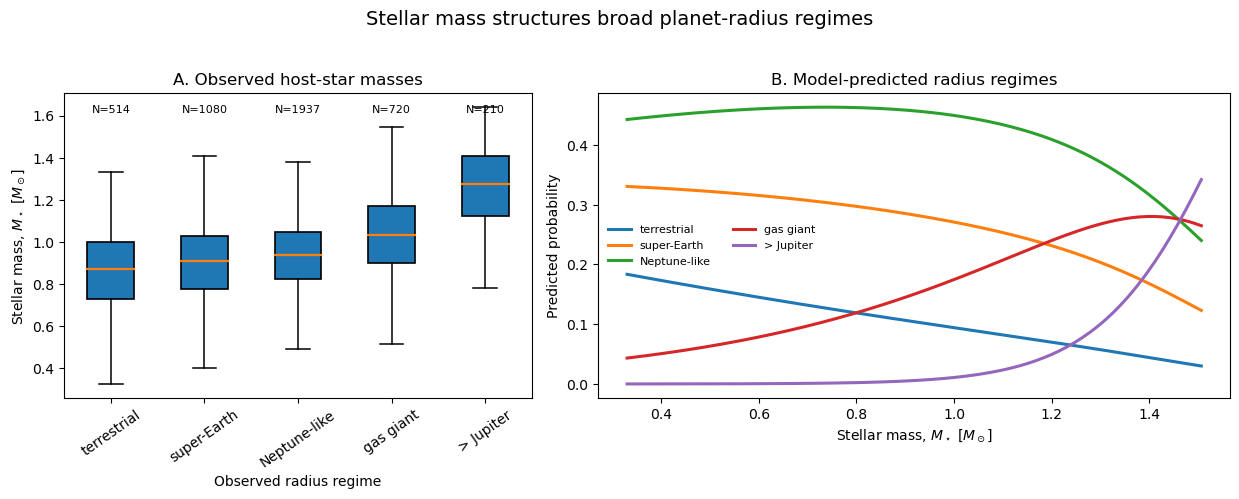

In [11]:
# ============================================================
# P21 — Final two-panel poster figure
# ============================================================

fig, axes = plt.subplots(
    1,
    2,
    figsize=(12.5, 4.8),
    gridspec_kw={"width_ratios": [1.0, 1.35]}
)

# ------------------------------------------------------------
# Panel A — observed Mstar distributions by class
# ------------------------------------------------------------

data_box = [
    df_panelA_plot.loc[
        df_panelA_plot["class_name"] == cls,
        "st_mass"
    ].dropna()
    for cls in plot_order
]

box = axes[0].boxplot(
    data_box,
    labels=plot_order,
    showfliers=False,
    patch_artist=True,
    medianprops={"linewidth": 1.6},
    boxprops={"linewidth": 1.2},
    whiskerprops={"linewidth": 1.1},
    capprops={"linewidth": 1.1}
)

# Do not force colors unless you want a specific poster palette.
# Matplotlib defaults are fine and readable.

axes[0].set_ylabel(r"Stellar mass, $M_\star$ [$M_\odot$]")
axes[0].set_xlabel("Observed radius regime")
axes[0].set_title("A. Observed host-star masses")

axes[0].tick_params(axis="x", rotation=35)

# Add N labels above each box
y_top = axes[0].get_ylim()[1]
for i, cls in enumerate(plot_order, start=1):
    n = int(counts_panelA.loc[cls])
    axes[0].text(
        i,
        y_top * 0.97,
        f"N={n}",
        ha="center",
        va="top",
        fontsize=8
    )

# ------------------------------------------------------------
# Panel B — predicted probabilities vs Mstar
# ------------------------------------------------------------

for cls in plot_order:
    axes[1].plot(
        tabla_P20_pred["st_mass"],
        tabla_P20_pred[cls],
        linewidth=2.2,
        label=cls
    )

axes[1].set_xlabel(r"Stellar mass, $M_\star$ [$M_\odot$]")
axes[1].set_ylabel("Predicted probability")
axes[1].set_title("B. Model-predicted radius regimes")

axes[1].legend(
    frameon=False,
    fontsize=8,
    ncol=2
)

# ------------------------------------------------------------
# Global formatting
# ------------------------------------------------------------

fig.suptitle(
    "Stellar mass structures broad planet-radius regimes",
    fontsize=14,
    y=1.03
)

plt.tight_layout()

plt.savefig(
    figures / "P21_poster_observed_and_predicted_Mstar_radius_regimes.png",
    dpi=300,
    bbox_inches="tight"
)

plt.savefig(
    figures / "P21_poster_observed_and_predicted_Mstar_radius_regimes.pdf",
    bbox_inches="tight"
)

plt.show()

In [12]:
# ============================================================
# Shared color palette for broad radius regimes
# ============================================================

class_colors = {
    "terrestrial": "tab:blue",
    "super-Earth": "tab:green",
    "Neptune-like": "tab:orange",
    "gas giant": "tab:red",
    "> Jupiter": "tab:purple"
}

plot_order = [
    "terrestrial",
    "super-Earth",
    "Neptune-like",
    "gas giant",
    "> Jupiter"
]

In [13]:
# ============================================================
# Panel A data — observed stellar mass by radius class
# ============================================================

code_class = {
    0: "super-Earth",
    1: "terrestrial",
    2: "Neptune-like",
    3: "gas giant",
    4: "> Jupiter"
}

# Create readable class labels if needed
if "class_name" not in df_p15.columns:
    if "class_code" in df_p15.columns:
        df_p15["class_name"] = df_p15["class_code"].map(code_class)
    elif "clase_radio" in df_p15.columns:
        rename_classes = {
            "terrestre": "terrestrial",
            "supertierra": "super-Earth",
            "neptuniano": "Neptune-like",
            "gigante_gaseoso": "gas giant",
            "mayor_que_jupiter": "> Jupiter"
        }
        df_p15["class_name"] = df_p15["clase_radio"].map(rename_classes)
    else:
        raise ValueError("Could not find class_code or clase_radio in df_p15.")

df_panelA = df_p15[
    df_p15["class_name"].isin(plot_order) &
    df_p15["st_mass"].notna()
].copy()

# Optional: remove extreme 1% tails only for poster readability
m_low = df_panelA["st_mass"].quantile(0.01)
m_high = df_panelA["st_mass"].quantile(0.99)

df_panelA_plot = df_panelA[
    (df_panelA["st_mass"] >= m_low) &
    (df_panelA["st_mass"] <= m_high)
].copy()

counts_panelA = (
    df_panelA
    .groupby("class_name")
    .size()
    .reindex(plot_order)
)

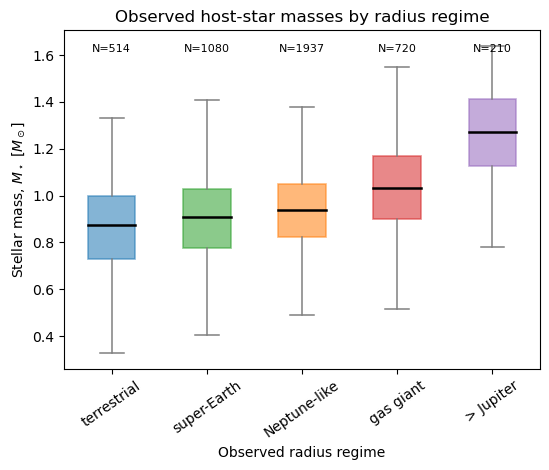

In [14]:
# ============================================================
# Save Panel A separately — colored boxplot
# ============================================================

import matplotlib.pyplot as plt
from pathlib import Path

figures = Path("../figures")
figures.mkdir(exist_ok=True)

fig, ax = plt.subplots(figsize=(5.6, 4.8))

data_box = [
    df_panelA_plot.loc[
        df_panelA_plot["class_name"] == cls,
        "st_mass"
    ].dropna()
    for cls in plot_order
]

box = ax.boxplot(
    data_box,
    labels=plot_order,
    showfliers=False,
    patch_artist=True,
    medianprops={
        "linewidth": 1.8,
        "color": "black"
    },
    boxprops={
        "linewidth": 1.2
    },
    whiskerprops={
        "linewidth": 1.1
    },
    capprops={
        "linewidth": 1.1
    }
)

# Apply same colors as probability curves
for patch, cls in zip(box["boxes"], plot_order):
    patch.set_facecolor(class_colors[cls])
    patch.set_alpha(0.55)
    patch.set_edgecolor(class_colors[cls])

for whisker in box["whiskers"]:
    whisker.set_color("gray")

for cap in box["caps"]:
    cap.set_color("gray")

ax.set_ylabel(r"Stellar mass, $M_\star$ [$M_\odot$]")
ax.set_xlabel("Observed radius regime")
ax.set_title("Observed host-star masses by radius regime")

ax.tick_params(axis="x", rotation=35)

# Add N labels
ymin, ymax = ax.get_ylim()
for i, cls in enumerate(plot_order, start=1):
    n = int(counts_panelA.loc[cls])
    ax.text(
        i,
        ymax - 0.04 * (ymax - ymin),
        f"N={n}",
        ha="center",
        va="top",
        fontsize=8
    )

plt.tight_layout()

plt.savefig(
    figures / "P21_panelA_observed_Mstar_by_radius_regime_colored.png",
    dpi=300,
    bbox_inches="tight"
)

plt.savefig(
    figures / "P21_panelA_observed_Mstar_by_radius_regime_colored.pdf",
    bbox_inches="tight"
)

plt.show()

In [15]:
# ============================================================
# Panel B data — predicted probabilities vs stellar mass
# ============================================================

import numpy as np
import pandas as pd
import statsmodels.api as sm

mstar_grid = np.linspace(
    df_p15["st_mass"].quantile(0.02),
    df_p15["st_mass"].quantile(0.98),
    150
)

grid_p20 = pd.DataFrame({
    "st_mass": mstar_grid
})

grid_p20["logP"] = df_p15["logP"].median()
grid_p20["st_met"] = df_p15["st_met"].median()

for var in ["logP", "st_mass", "st_met"]:
    grid_p20[var + "_z"] = (
        grid_p20[var] - df_p15[var].mean()
    ) / df_p15[var].std()

X_grid_p20 = grid_p20[
    [
        "logP_z",
        "st_mass_z",
        "st_met_z"
    ]
].copy()

X_grid_p20 = sm.add_constant(
    X_grid_p20,
    has_constant="add"
)

pred_p20 = modelo_p15.predict(X_grid_p20)

tabla_P20_pred = pred_p20.copy()
tabla_P20_pred.columns = [
    code_class[i] for i in range(pred_p20.shape[1])
]
tabla_P20_pred["st_mass"] = mstar_grid

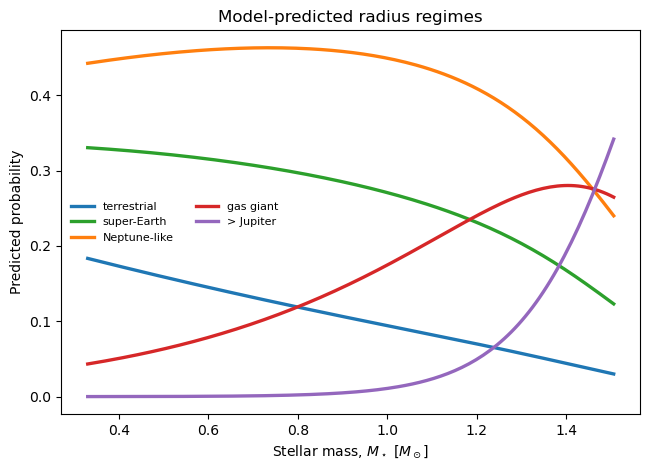

In [16]:
# ============================================================
# Save Panel B separately — same colors as Panel A
# ============================================================

fig, ax = plt.subplots(figsize=(6.6, 4.8))

for cls in plot_order:
    ax.plot(
        tabla_P20_pred["st_mass"],
        tabla_P20_pred[cls],
        linewidth=2.4,
        color=class_colors[cls],
        label=cls
    )

ax.set_xlabel(r"Stellar mass, $M_\star$ [$M_\odot$]")
ax.set_ylabel("Predicted probability")
ax.set_title("Model-predicted radius regimes")

ax.legend(
    frameon=False,
    fontsize=8,
    ncol=2
)

plt.tight_layout()

plt.savefig(
    figures / "P21_panelB_predicted_probabilities_vs_Mstar_colored.png",
    dpi=300,
    bbox_inches="tight"
)

plt.savefig(
    figures / "P21_panelB_predicted_probabilities_vs_Mstar_colored.pdf",
    bbox_inches="tight"
)

plt.show()

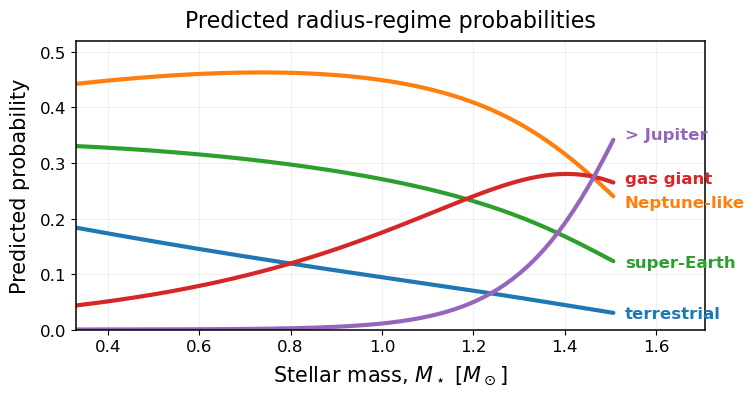

In [19]:
# ============================================================
# Poster-ready figure: predicted radius-regime probabilities
# Direct labels, no legend
# Put in: 08b_outcome_I_broad_radius_regime.ipynb
# Run after tabla_P20_pred exists
# ============================================================

import matplotlib.pyplot as plt
from pathlib import Path

figures = Path("../figures")
figures.mkdir(exist_ok=True)

# Shared colors
class_colors = {
    "terrestrial": "tab:blue",
    "super-Earth": "tab:green",
    "Neptune-like": "tab:orange",
    "gas giant": "tab:red",
    "> Jupiter": "tab:purple"
}

plot_order = [
    "terrestrial",
    "super-Earth",
    "Neptune-like",
    "gas giant",
    "> Jupiter"
]

# More poster-like sizing
plt.rcParams.update({
    "font.size": 14,
    "axes.titlesize": 16,
    "axes.labelsize": 15,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
})

fig, ax = plt.subplots(figsize=(7.8, 4.2))

# Plot lines
for cls in plot_order:
    ax.plot(
        tabla_P20_pred["st_mass"],
        tabla_P20_pred[cls],
        linewidth=3.0,
        color=class_colors[cls],
        solid_capstyle="round"
    )

# Direct labels near curves
label_x = tabla_P20_pred["st_mass"].iloc[-1]
x_offset = 0.025

label_offsets = {
    "terrestrial": -0.002,
    "super-Earth": -0.002,
    "Neptune-like": -0.012,
    "gas giant": 0.008,
    "> Jupiter": 0.010
}

for cls in plot_order:
    y_end = tabla_P20_pred[cls].iloc[-1] + label_offsets[cls]

    ax.text(
        label_x + x_offset,
        y_end,
        cls,
        color=class_colors[cls],
        fontsize=12,
        fontweight="bold",
        va="center"
    )

# Axis labels
ax.set_xlabel(r"Stellar mass, $M_\star$ [$M_\odot$]", labelpad=7)
ax.set_ylabel("Predicted probability", labelpad=7)

# More interpretive title
ax.set_title(
    r"Predicted radius-regime probabilities",
    pad=10
)

# Limits leave room for direct labels
ax.set_xlim(
    tabla_P20_pred["st_mass"].min(),
    tabla_P20_pred["st_mass"].max() + 0.20
)

ax.set_ylim(0, 0.52)

# Clean grid and frame
ax.grid(
    alpha=0.18,
    linewidth=0.8
)

for spine in ax.spines.values():
    spine.set_linewidth(1.1)


plt.tight_layout()

plt.savefig(
    figures / "P21_predicted_probabilities_vs_Mstar_direct_labels.pdf",
    bbox_inches="tight"
)

plt.savefig(
    figures / "P21_predicted_probabilities_vs_Mstar_direct_labels.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()